In [16]:
%pip install lightgbm shap -q

Note: you may need to restart the kernel to use updated packages.


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import lightgbm as lgb
import shap
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

RED, BLUE, GREY, PINK = '#00703C', '#7FBF9A', '#BDBDBD', '#A8D5BA'   # dark green, light green, grey, pale green
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})

CUTOFF = 202602   # model only sees data through Feb 2026 (closures happen Mar–Jun)

In [18]:
df = pd.read_parquet("Datathon_Hard_Attrition_Final.parquet")
df = df.sort_values(['TOKEN_ID', 'MONTHEND']).reset_index(drop=True)
print(df.shape, "|", df['TOKEN_ID'].nunique(), "customers x", df['MONTHEND'].nunique(), "months")

(120000, 58) | 10000 customers x 12 months


In [19]:
spend_all = [c for c in df.columns if c.endswith('_SPEND') or c.endswith('_SPENDING')]

quality = pd.DataFrame([
    ['Age over 100 (birth date unknown)',          (df['AGE'] > 100).sum(),                 'Marked as unknown'],
    ['Credit score recorded as 0',                 (df['MONTHEND_FICO_SCORE'] == 0).sum(),  'Marked as unknown'],
    ['Booked credit score recorded as 0',          (df['BOOKED_FICO'] == 0).sum(),          'Column not used'],
    ['Behavior score below 300 (special code)',    (df['BEHAVIOR_SCORE'] < 300).sum(),      'Marked as unknown'],
    ['Account age over 50 years',                  (df['MONTH_ON_BOOKS'] > 600).sum(),      'Capped at 50 years'],
    ['Negative utilization (overpayment)',         (df['UTILIZATION_RATE'] < 0).sum(),      'Kept: real reversals'],
    ['Negative spending (refunds)',                (df[spend_all] < 0).any(axis=1).sum(),   'Kept: real refunds'],
    ['Missing behavior segment',                   df['BEHAVIOR_SEGMENT'].isna().sum(),     'Labeled "Unknown"'],
], columns=['Issue', 'Rows affected', 'What we did'])
quality['% of rows'] = (quality['Rows affected'] / len(df) * 100).round(1)
quality

,Issue,Rows affected,What we did,% of rows
0,Age over 100 (birth date unknown),92,Marked as unknown,0.1
1,Credit score recorded as 0,114,Marked as unknown,0.1
2,Booked credit score recorded as 0,19488,Column not used,16.2
3,Behavior score below 300 (special code),2714,Marked as unknown,2.3
4,Account age over 50 years,176,Capped at 50 years,0.1
5,Negative utilization (overpayment),272,Kept: real reversals,0.2
6,Negative spending (refunds),2751,Kept: real refunds,2.3
7,Missing behavior segment,2190,"Labeled ""Unknown""",1.8


In [20]:
yn_cols = ['HARD_ATTR_IND', 'SOFT_ATTR_IND', 'AUTOPAY_IND', 'ONLINE_ENROLLMENT',
           'ESTATEMENT_ENROLLMENT', 'ANNUAL_FEE_IND', 'FRAUD_IND', 'STOLEN_IND']
df[yn_cols] = (df[yn_cols] == 'Y').astype(int)

df['age_missing'] = (df['AGE'] > 100).astype(int)
df.loc[df['AGE'] > 100, 'AGE'] = np.nan

df['fico_missing'] = (df['MONTHEND_FICO_SCORE'] == 0).astype(int)
df.loc[df['MONTHEND_FICO_SCORE'] == 0, 'MONTHEND_FICO_SCORE'] = np.nan

df['behavior_score_missing'] = (df['BEHAVIOR_SCORE'] < 300).astype(int)
df.loc[df['BEHAVIOR_SCORE'] < 300, 'BEHAVIOR_SCORE'] = np.nan

df['MONTH_ON_BOOKS'] = df['MONTH_ON_BOOKS'].clip(upper=600)
df['credit_balance'] = (df['UTILIZATION_RATE'] < 0).astype(int)
df['UTILIZATION_RATE'] = df['UTILIZATION_RATE'].clip(-1, 2)
df['BEHAVIOR_SEGMENT'] = df['BEHAVIOR_SEGMENT'].fillna('Unknown')

# SOFT_ATTR_IND leaks the answer; fee columns duplicate their amounts; BOOKED_FICO is 16% zeros
df = df.drop(columns=['SOFT_ATTR_IND', 'BT_FEE', 'CASH_ADVANCE_FEE', 'BOOKED_FICO'])

print("Target values:", sorted(df['HARD_ATTR_IND'].unique()), "| max age:", df['AGE'].max())

Target values: [np.int64(0), np.int64(1)] | max age: 100.0


In [21]:
w = df[df['MONTHEND'] <= CUTOFF].copy()
months = sorted(w['MONTHEND'].unique())
first3, last3 = months[:3], months[-3:]

spend_cols = [c for c in spend_all if c not in ('MONTHLY_SPEND', 'ON_PARTNER_SPEND')]
w['n_categories'] = (w[spend_cols] > 0).sum(axis=1)
w['wallet_share'] = (w['MONTHLY_BALANCE'] / w['BUREAU_BALANCE'].where(w['BUREAU_BALANCE'] > 0)).clip(-1, 2)
w['pay_ratio']    = (w['MONTHLY_PAYMENT'] / w['MONTHLY_BALANCE'].where(w['MONTHLY_BALANCE'] > 0)).clip(0, 5)

g = w.groupby('TOKEN_ID')
f = pd.DataFrame(index=g.size().index)

def trend(col):
    early = w[w['MONTHEND'].isin(first3)].groupby('TOKEN_ID')[col].mean()
    late  = w[w['MONTHEND'].isin(last3)].groupby('TOKEN_ID')[col].mean()
    return late - early, late

for col in ['NUM_TRANSACTIONS', 'MONTHLY_SPEND', 'MONTHLY_BALANCE', 'UTILIZATION_RATE',
            'n_categories', 'wallet_share', 'ON_PARTNER_SPEND']:
    f[col + '_chg'], f[col + '_last3'] = trend(col)

f['zero_txn_months']   = (w['NUM_TRANSACTIONS'] == 0).groupby(w['TOKEN_ID']).sum()
f['pay_ratio_mean']    = g['pay_ratio'].mean()
f['redeemed_total']    = g['REDEEMED_POINTS'].sum()
f['rewards_last']      = g['AVAILABLE_REWARDS'].last()
f['annual_fee_posted'] = (g['ANNUAL_FEE'].sum() > 0).astype(int)
f['late_fees']         = g['LATE_FEE'].sum()
f['finance_charges']   = g['FINANCE_CHARGE'].sum()
f['cash_adv']          = g['CASH_ADVANCE_AMT'].sum()
f['bt_amt']            = g['BT_AMT'].sum()
f['autopay_dropped']   = ((g['AUTOPAY_IND'].first() == 1) & (g['AUTOPAY_IND'].last() == 0)).astype(int)
f['fico_chg']          = g['MONTHEND_FICO_SCORE'].last() - g['MONTHEND_FICO_SCORE'].first()
f['bureau_30dpd']      = g['BUREAU_30DPD_COUNT'].max()
f['ever_delinq']       = g['IS_DELIQUENT'].max()
f['fraud_or_stolen']   = g['FRAUD_IND'].max() | g['STOLEN_IND'].max()

static = ['MONTH_ON_BOOKS', 'AGE', 'age_missing', 'PROD_TYPE', 'BEHAVIOR_SEGMENT',
          'ANNUAL_FEE_IND', 'ONLINE_ENROLLMENT', 'ESTATEMENT_ENROLLMENT', 'AUTOPAY_IND',
          'CREDIT_LIMIT', 'BEHAVIOR_SCORE', 'behavior_score_missing',
          'PROFIT_SCORE', 'MONTHEND_FICO_SCORE', 'fico_missing']
f = f.join(g[static].last())
f['y'] = df.groupby('TOKEN_ID')['HARD_ATTR_IND'].max()

f = pd.get_dummies(f, columns=['PROD_TYPE', 'BEHAVIOR_SEGMENT'], dtype=int)
f.columns = f.columns.str.replace(r'[^0-9a-zA-Z_]', '_', regex=True)   # LightGBM-safe names

# Annual value per customer (for the business-impact slide only; NOT a model input)
INTERCHANGE = 0.02   # assumption: FNBO earns ~2% of card spend
value = ((g['FINANCE_CHARGE'].sum() + g['ANNUAL_FEE'].sum() + g['LATE_FEE'].sum()
          + INTERCHANGE * g['MONTHLY_SPEND'].sum().clip(lower=0)) * 12 / len(months))

AVG = f['y'].mean()
print("Customer table:", f.shape, "| attrition rate:", round(AVG, 3))

Customer table: (10000, 52) | attrition rate: 0.2


In [22]:
X, y = f.drop(columns='y'), f['y']

model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                           min_child_samples=50, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, random_state=42, verbose=-1)

# Honest risk score for every customer: 5-fold, each scored by a model that never saw them
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk = pd.Series(cross_val_predict(model, X, y, cv=cv, method='predict_proba')[:, 1], index=X.index)

# Final model on all customers (used for the "why" / drivers)
model.fit(X, y)

auc = roc_auc_score(y, risk)
print("AUC:", round(auc, 3), "(0.5 = random guessing)")
if auc > 0.95:
    print("WARNING: suspiciously high, check for leakage")

ranked = pd.DataFrame({'risk': risk, 'y': y}).sort_values('risk', ascending=False)
for k in (0.1, 0.2, 0.3):
    caught = ranked.head(int(len(ranked) * k))['y'].sum() / ranked['y'].sum()
    print(f"Contact top {int(k*100)}% → reach {caught:.0%} of leavers (random: {int(k*100)}%)")

AUC: 0.672 (0.5 = random guessing)
Contact top 10% → reach 21% of leavers (random: 10%)
Contact top 20% → reach 36% of leavers (random: 20%)
Contact top 30% → reach 48% of leavers (random: 30%)


In [23]:
def rate_chart(groups, title, fname, good=False, order=None):
    """Bar chart of % who left. good=True highlights the LOWEST bar in blue (good news)."""
    t = f.groupby(groups, observed=True)['y'].agg(['mean', 'count'])
    if order:
        t = t.reindex(order)
    pick = t['mean'].idxmin() if good else t['mean'].idxmax()
    colors = [(BLUE if good else RED) if i == pick else GREY for i in t.index]

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(t.index.astype(str), t['mean'] * 100, color=colors, width=0.6)
    ax.axhline(AVG * 100, ls='--', color='black', lw=1)
    ax.text(-0.45, AVG * 100 + 1.2, f'Average: {AVG:.0%}', ha='left', fontsize=11)
    for b, (m, n) in zip(bars, t.values):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f'{m:.0%}',
                ha='center', fontsize=15, weight='bold')
        ax.text(b.get_x() + b.get_width() / 2, 1.5, f'{int(n):,} customers',
                ha='center', fontsize=9, color='white')
    ax.set_title(title, loc='left', fontsize=16, weight='bold', pad=15)
    ax.set_ylabel('% who closed their card')
    ax.set_ylim(0, max(t['mean'].max() * 100 + 12, 35))
    ax.set_yticks([])
    plt.tight_layout(); plt.savefig(fname, dpi=200); plt.show()

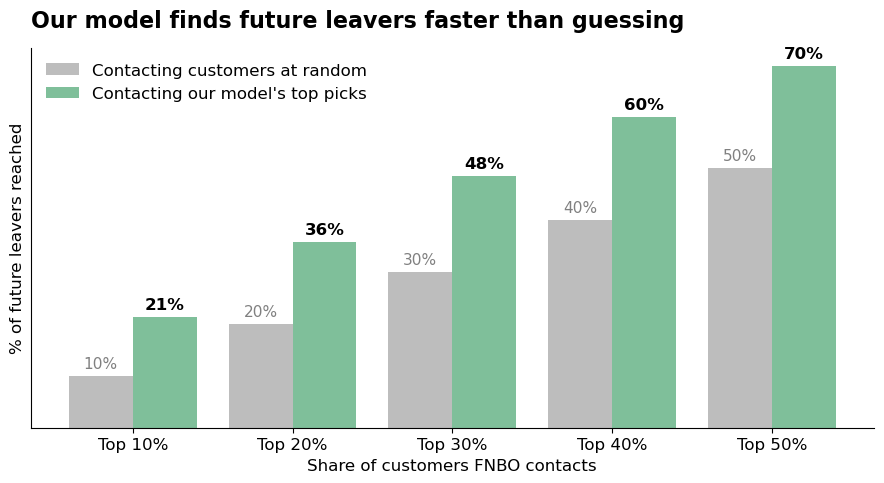

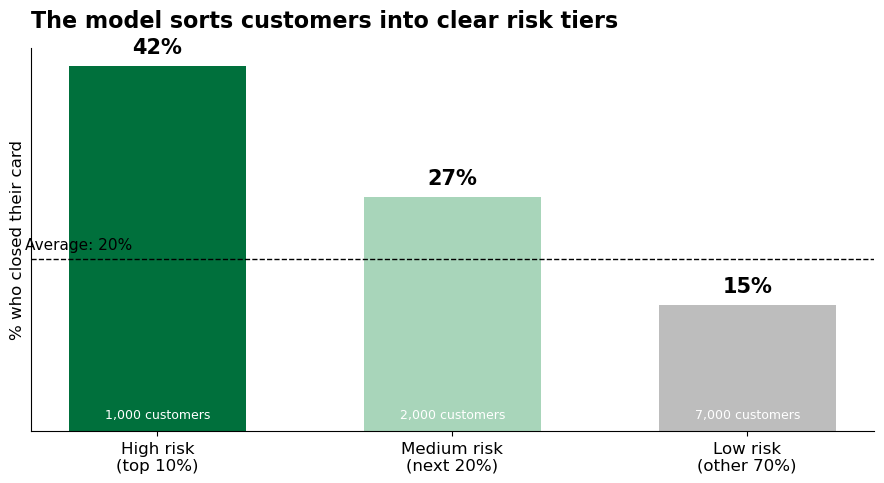

tier,High risk,Medium risk,Low risk
Has an annual fee,24%,5%,2%
Customer under 2 years,31%,16%,4%
Dropped 3+ spending categories,18%,6%,2%
Card usage dropped,57%,45%,42%
Shops at partner stores,11%,10%,24%


In [24]:
# --- Slide: the model finds leavers faster than guessing ---
pcts = [10, 20, 30, 40, 50]
caught = [ranked.head(int(len(ranked) * p / 100))['y'].sum() / ranked['y'].sum() * 100 for p in pcts]
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(pcts))
ax.bar(x - 0.2, pcts, 0.4, color=GREY, label='Contacting customers at random')
ax.bar(x + 0.2, caught, 0.4, color=BLUE, label="Contacting our model's top picks")
for i in range(len(pcts)):
    ax.text(i - 0.2, pcts[i] + 1.5, f'{pcts[i]}%', ha='center', fontsize=11, color='grey')
    ax.text(i + 0.2, caught[i] + 1.5, f'{caught[i]:.0f}%', ha='center', fontsize=12, weight='bold')
ax.set_xticks(x, [f'Top {p}%' for p in pcts])
ax.set_xlabel('Share of customers FNBO contacts'); ax.set_ylabel('% of future leavers reached')
ax.set_yticks([])
ax.set_title('Our model finds future leavers faster than guessing', loc='left', fontsize=16, weight='bold', pad=15)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('chart_model_value.png', dpi=200); plt.show()

# --- Slide: risk tiers ---
f['tier'] = pd.qcut(risk.rank(method='first', ascending=False), [0, 0.10, 0.30, 1.0],
                    labels=['High risk', 'Medium risk', 'Low risk'])
t = f.groupby('tier', observed=True)['y'].agg(['mean', 'count'])
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(range(3), t['mean'] * 100, color=[RED, PINK, GREY], width=0.6)
ax.axhline(AVG * 100, ls='--', color='black', lw=1)
ax.text(-0.45, AVG * 100 + 1.2, f'Average: {AVG:.0%}', ha='left', fontsize=11)
for b, (m, n) in zip(bars, t.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f'{m:.0%}', ha='center', fontsize=15, weight='bold')
    ax.text(b.get_x() + b.get_width() / 2, 1.5, f'{int(n):,} customers', ha='center', fontsize=9, color='white')
ax.set_xticks(range(3), ['High risk\n(top 10%)', 'Medium risk\n(next 20%)', 'Low risk\n(other 70%)'])
ax.set_ylabel('% who closed their card'); ax.set_yticks([])
ax.set_title('The model sorts customers into clear risk tiers', loc='left', fontsize=16, weight='bold', pad=15)
plt.tight_layout(); plt.savefig('chart_risk_tiers.png', dpi=200); plt.show()

# --- Slide: who is in the high-risk tier? (the bridge to the support charts) ---
tg = f.groupby('tier', observed=True)
profile = pd.DataFrame({
    'Has an annual fee':            tg['ANNUAL_FEE_IND'].mean(),
    'Customer under 2 years':       tg['MONTH_ON_BOOKS'].apply(lambda s: (s < 24).mean()),
    'Dropped 3+ spending categories': tg['n_categories_chg'].apply(lambda s: (s <= -3).mean()),
    'Card usage dropped':           tg['NUM_TRANSACTIONS_chg'].apply(lambda s: (s < 0).mean()),
    'Shops at partner stores':      tg['ON_PARTNER_SPEND_last3'].apply(lambda s: (s > 0).mean()),
}).T
(profile * 100).round(0).astype(int).astype(str) + '%'

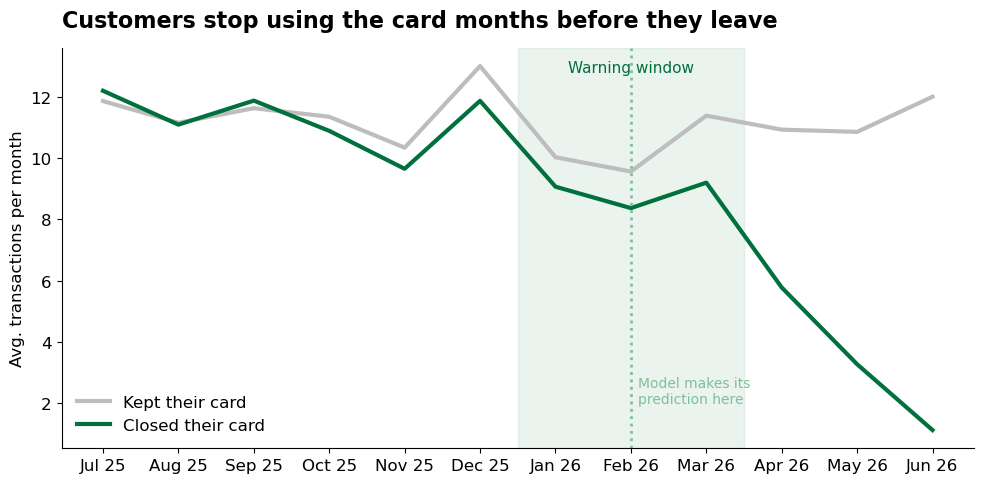

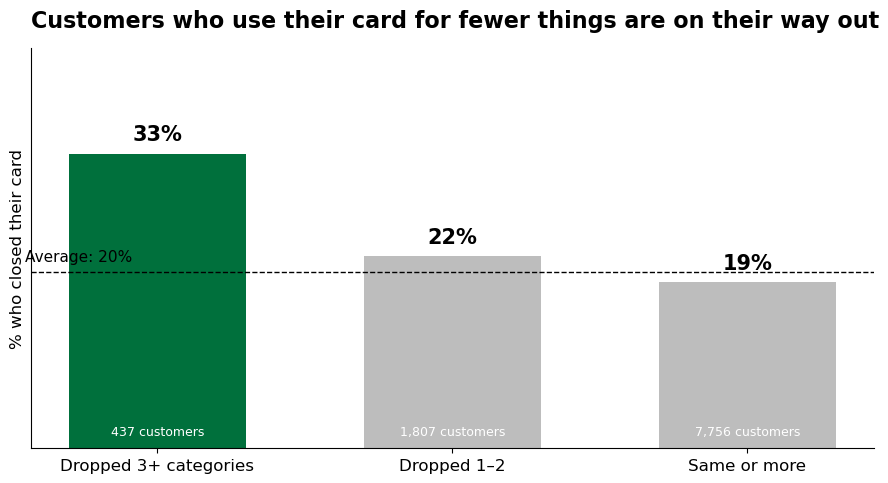

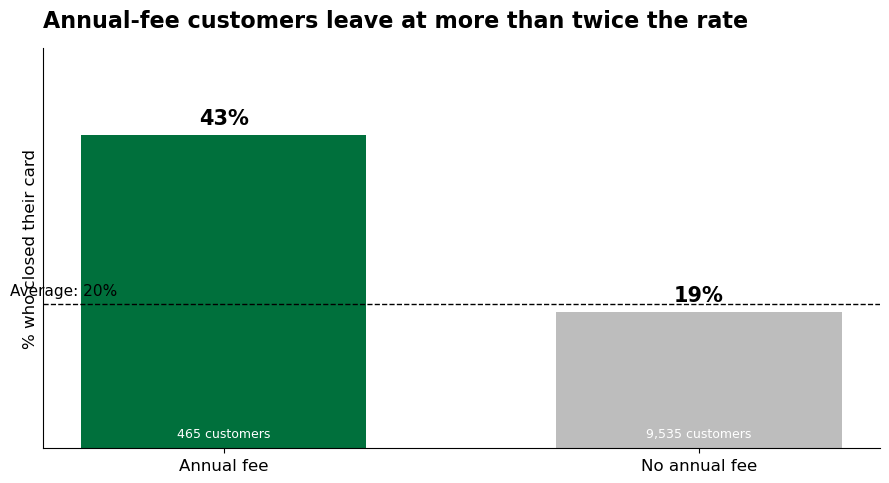

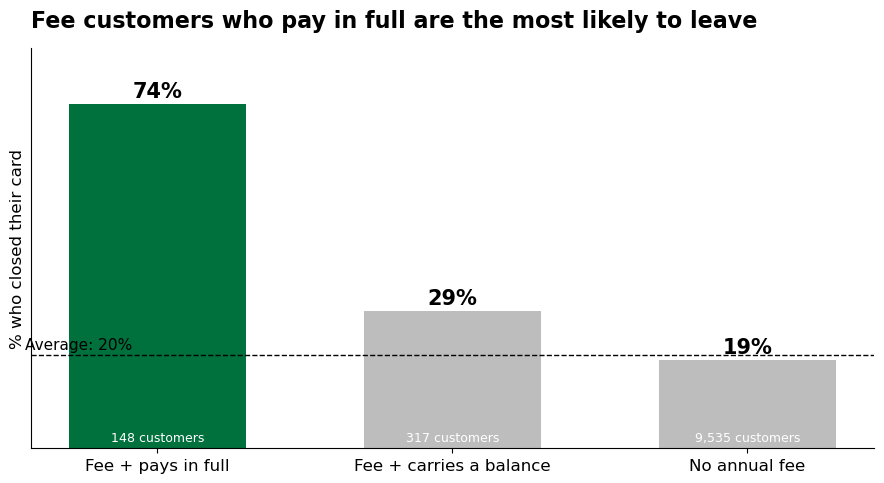

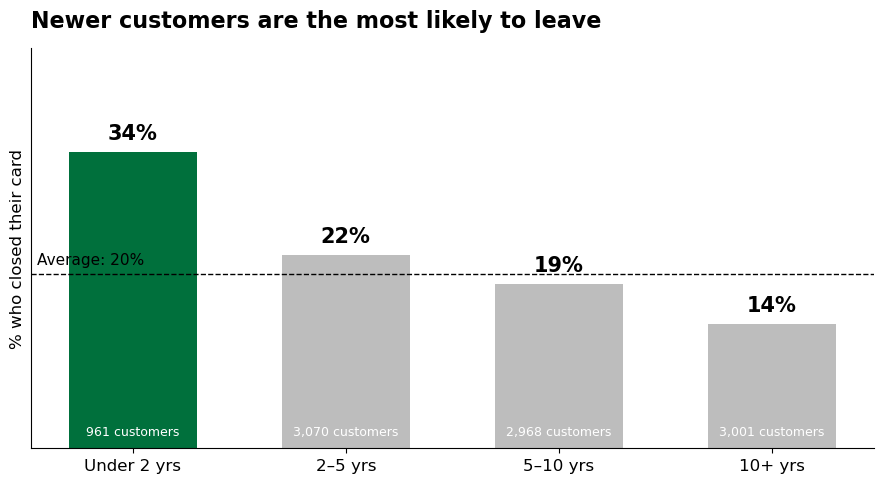

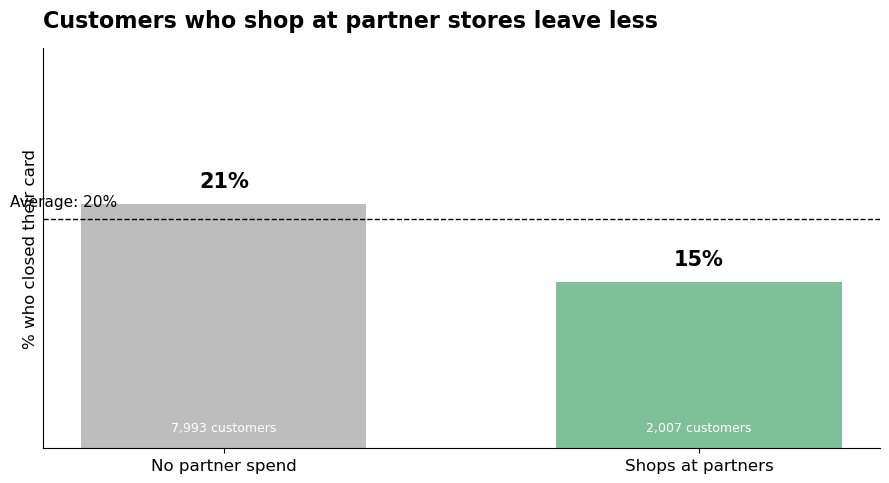

In [25]:
# --- Driver 1: fading usage (the warning window) ---
trend_m = df.groupby(['MONTHEND', 'HARD_ATTR_IND'])['NUM_TRANSACTIONS'].mean().unstack()
xm = np.arange(len(trend_m))
labels = pd.to_datetime(trend_m.index.astype(str), format='%Y%m').strftime('%b %y')
cut = list(trend_m.index).index(CUTOFF)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(xm, trend_m[0], color=GREY, lw=3, label='Kept their card')
ax.plot(xm, trend_m[1], color=RED, lw=3, label='Closed their card')
ax.axvspan(cut - 1.5, cut + 1.5, color=RED, alpha=0.08)
ax.axvline(cut, ls=':', color=BLUE, lw=2)
ax.text(cut + 0.1, 2, 'Model makes its\nprediction here', color=BLUE, fontsize=10)
ax.text(cut, ax.get_ylim()[1] * 0.97, 'Warning window', ha='center', va='top', color=RED, fontsize=11)
ax.set_xticks(xm, labels)
ax.set_ylabel('Avg. transactions per month')
ax.set_title('Customers stop using the card months before they leave', loc='left', fontsize=16, weight='bold', pad=15)
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.savefig('chart_warning_window.png', dpi=200); plt.show()

rate_chart(pd.cut(f['n_categories_chg'], [-np.inf, -3, -1, np.inf],
                  labels=['Dropped 3+ categories', 'Dropped 1–2', 'Same or more']),
           'Customers who use their card for fewer things are on their way out',
           'chart_categories.png')

# --- Driver 2: the annual fee ---
rate_chart(f['ANNUAL_FEE_IND'].map({1: 'Annual fee', 0: 'No annual fee'}),
           'Annual-fee customers leave at more than twice the rate', 'chart_fee.png',
           order=['Annual fee', 'No annual fee'])

trans_col = [c for c in f.columns if 'Transactor' in c][0]
fee_groups = pd.Series(np.select(
    [(f['ANNUAL_FEE_IND'] == 1) & (f[trans_col] == 1),
     (f['ANNUAL_FEE_IND'] == 1) & (f[trans_col] == 0)],
    ['Fee + pays in full', 'Fee + carries a balance'], default='No annual fee'), index=f.index)
rate_chart(fee_groups, 'Fee customers who pay in full are the most likely to leave',
           'chart_fee_transactor.png',
           order=['Fee + pays in full', 'Fee + carries a balance', 'No annual fee'])

# --- Driver 3: new customers ---
rate_chart(pd.cut(f['MONTH_ON_BOOKS'], [0, 24, 60, 120, 601],
                  labels=['Under 2 yrs', '2–5 yrs', '5–10 yrs', '10+ yrs']),
           'Newer customers are the most likely to leave', 'chart_tenure.png')

# --- What keeps customers ---
rate_chart((f['ON_PARTNER_SPEND_last3'] > 0).map({True: 'Shops at partners', False: 'No partner spend'}),
           'Customers who shop at partner stores leave less', 'chart_partner.png',
           good=True, order=['No partner spend', 'Shops at partners'])

In [26]:
SAVE_RATE = 0.20   # assumption: retention offer saves 1 in 5 contacted leavers
COST      = 25     # assumption: $ per customer contacted (call + offer)

rows = []
for name, mask in [('High risk only (top 10%)', f['tier'] == 'High risk'),
                   ('High + Medium (top 30%)', f['tier'].isin(['High risk', 'Medium risk']))]:
    grp = f[mask]
    leavers = grp['y'].sum()
    saved = leavers * SAVE_RATE
    value_saved = saved * value[grp.index[grp['y'] == 1]].mean()
    cost = len(grp) * COST
    rows.append([name, len(grp), int(leavers), round(saved), round(value_saved), cost, round(value_saved - cost)])

impact = pd.DataFrame(rows, columns=['Who FNBO contacts', 'Customers', 'Future leavers in group',
                                     'Customers saved', 'Annual value saved ($)', 'Campaign cost ($)', 'Net benefit ($)'])
print(f"Avg annual value of a customer who left: ${value[f['y'] == 1].mean():,.0f}")
print("Based on this 10,000-customer sample. Scale up to FNBO's full card portfolio.")
impact

Avg annual value of a customer who left: $1,145
Based on this 10,000-customer sample. Scale up to FNBO's full card portfolio.


,Who FNBO contacts,Customers,Future leavers in group,Customers saved,Annual value saved ($),Campaign cost ($),Net benefit ($)
0,High risk only (top 10%),1000,425,85,99045,25000,74045
1,High + Medium (top 30%),3000,970,194,225256,75000,150256


/Applications/anaconda3/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/Applications/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Applications/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/Applications/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Applications/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


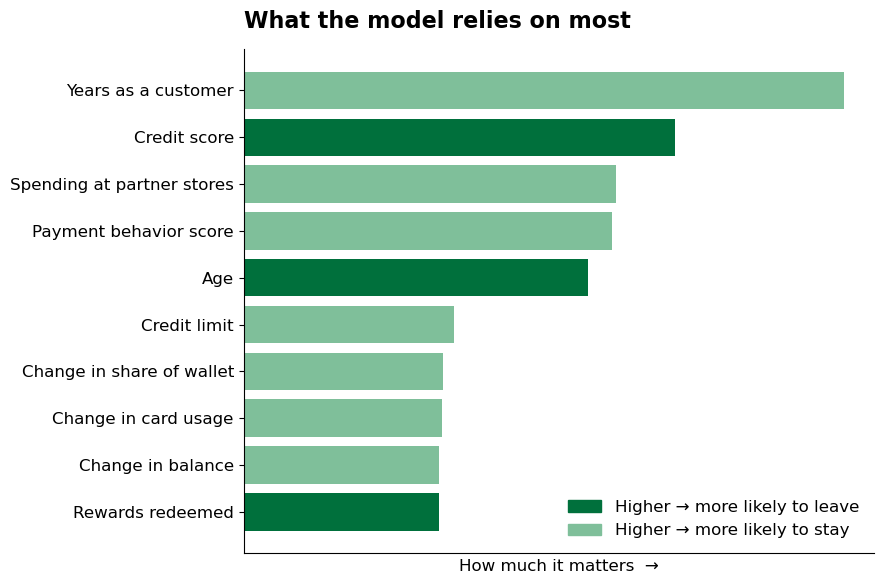

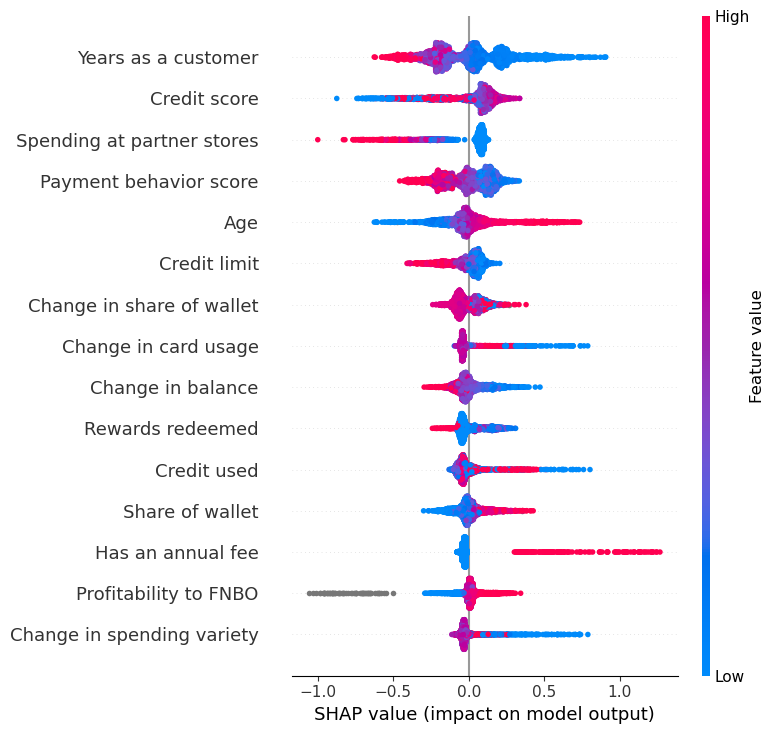

In [12]:
# Top drivers in plain English
nice = {'MONTH_ON_BOOKS': 'Years as a customer', 'MONTHEND_FICO_SCORE': 'Credit score',
        'BEHAVIOR_SCORE': 'Payment behavior score', 'AGE': 'Age',
        'ON_PARTNER_SPEND_last3': 'Spending at partner stores', 'CREDIT_LIMIT': 'Credit limit',
        'PROFIT_SCORE': 'Profitability to FNBO', 'NUM_TRANSACTIONS_chg': 'Change in card usage',
        'ANNUAL_FEE_IND': 'Has an annual fee', 'n_categories_chg': 'Change in spending variety',
        'UTILIZATION_RATE_last3': 'Credit used', 'redeemed_total': 'Rewards redeemed',
        'wallet_share_chg': 'Change in share of wallet', 'wallet_share_last3': 'Share of wallet',
        'MONTHLY_BALANCE_chg': 'Change in balance'}

Xs = X.sample(3000, random_state=42)
sv = shap.TreeExplainer(model).shap_values(Xs)
if isinstance(sv, list):
    sv = sv[1]

imp = pd.Series(np.abs(sv).mean(axis=0), index=Xs.columns)
direction = pd.Series({c: np.corrcoef(Xs[c].fillna(Xs[c].median()), sv[:, i])[0, 1]
                       for i, c in enumerate(Xs.columns)}).fillna(0)
top = imp.nlargest(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([nice.get(c, c) for c in top.index], top.values,
        color=[RED if direction[c] > 0 else BLUE for c in top.index])
ax.set_xticks([]); ax.set_xlabel('How much it matters  →')
ax.set_title('What the model relies on most', loc='left', fontsize=16, weight='bold', pad=15)
ax.legend(handles=[Patch(color=RED, label='Higher → more likely to leave'),
                   Patch(color=BLUE, label='Higher → more likely to stay')], frameon=False, loc='lower right')
plt.tight_layout(); plt.savefig('backup_drivers.png', dpi=200); plt.show()

# Full SHAP chart for technical judges
shap.summary_plot(sv, Xs.rename(columns=nice), max_display=15, show=False)
plt.tight_layout(); plt.savefig('backup_shap.png', dpi=200, bbox_inches='tight'); plt.show()

In [27]:
print(f"Customers: {len(f):,} | Left: {int(f['y'].sum()):,} ({AVG:.0%})")
print(f"Model AUC: {auc:.2f}")
for k in (0.1, 0.2):
    c = ranked.head(int(len(ranked) * k))['y'].sum() / ranked['y'].sum()
    print(f"Top {int(k*100)}% riskiest → {c:.0%} of leavers ({c / k:.1f}x random)")
print(f"High-risk tier leave rate: {f.loc[f['tier'] == 'High risk', 'y'].mean():.0%}")

Customers: 10,000 | Left: 2,000 (20%)
Model AUC: 0.67
Top 10% riskiest → 21% of leavers (2.1x random)
Top 20% riskiest → 36% of leavers (1.8x random)
High-risk tier leave rate: 42%


In [ ]:
   print(f"Annual value lost from leavers: ${value[f['y'] == 1].sum():,.0f}")

                                Contact top 10% Contact top 30%
Customers contacted                       1,000           3,000
Future leavers in the group                 425             970
Customers saved (20% save rate)              85             194
Annual value saved                         $99K           $225K
Outreach cost ($25 each)                   $25K            $75K
Net benefit                                $74K           $150K


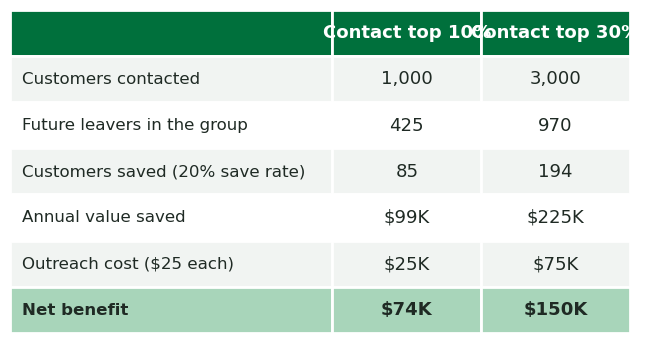

Assumptions: ~2% interchange, 1 in 5 contacted leavers saved, $25 per contact. Based on a 10,000-customer sample.


In [30]:
# ===== Business impact table (green & grey) =====
from matplotlib.patches import Rectangle

SAVE_RATE = 0.20   # assumption: outreach saves 1 in 5 contacted leavers
COST      = 25     # assumption: $ per customer contacted

def money(x):
    sign = '-' if x < 0 else ''
    x = abs(x)
    if x >= 1_000_000: return f"{sign}${x/1_000_000:.1f}M"
    if x >= 1_000:     return f"{sign}${x/1_000:.0f}K"
    return f"{sign}${x:,.0f}"

# --- calculate ---
results = {}
for label, mask in [('Contact top 10%', f['tier'] == 'High risk'),
                    ('Contact top 30%', f['tier'].isin(['High risk', 'Medium risk']))]:
    grp = f[mask]
    leavers = int(grp['y'].sum())
    saved = leavers * SAVE_RATE
    value_saved = saved * value[grp.index[grp['y'] == 1]].mean()
    cost = len(grp) * COST
    results[label] = [f"{len(grp):,}", f"{leavers:,}", f"{round(saved):,}",
                      money(value_saved), money(cost), money(value_saved - cost)]

row_labels = ['Customers contacted', 'Future leavers in the group',
              'Customers saved (20% save rate)', 'Annual value saved',
              'Outreach cost ($25 each)', 'Net benefit']
tbl = pd.DataFrame(results, index=row_labels)
print(tbl)

# --- draw ---
GREEN, GREEN_LT, GREY_LT, DARK = '#00703C', '#A8D5BA', '#F1F4F2', '#1F2A24'
n_rows = len(row_labels) + 1
rh = 1 / n_rows
col_x = [0.00, 0.52, 0.76]
col_w = [0.52, 0.24, 0.24]
headers = [''] + list(tbl.columns)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')

# header row
y = 1 - rh
for x, w, h in zip(col_x, col_w, headers):
    ax.add_patch(Rectangle((x, y), w, rh, facecolor=GREEN, edgecolor='white', lw=2))
    ax.text(x + w / 2, y + rh / 2, h, ha='center', va='center', color='white', fontsize=13, weight='bold')

# body rows
for i, lab in enumerate(row_labels):
    y = 1 - rh * (i + 2)
    last = (i == len(row_labels) - 1)
    fill = GREEN_LT if last else (GREY_LT if i % 2 == 0 else 'white')
    weight = 'bold' if last else 'normal'
    cells = [lab] + list(tbl.loc[lab])
    for j, (x, w, val) in enumerate(zip(col_x, col_w, cells)):
        ax.add_patch(Rectangle((x, y), w, rh, facecolor=fill, edgecolor='white', lw=2))
        if j == 0:
            ax.text(x + 0.02, y + rh / 2, val, ha='left', va='center', color=DARK, fontsize=12, weight=weight)
        else:
            ax.text(x + w / 2, y + rh / 2, val, ha='center', va='center', color=DARK, fontsize=13, weight=weight)

plt.savefig('impact_table.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()

print("Assumptions: ~2% interchange, 1 in 5 contacted leavers saved, $25 per contact. Based on a 10,000-customer sample.")